In [1]:
import os, copy, json, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from torchvision.utils import make_grid
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

cuda NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
MODEL_NAME = "vae"
DATA_DIR = "data"
CKPT_DIR = "checkpoints"
FIG_DIR = "figures"
RESULTS_DIR = "results"
for d in (DATA_DIR, CKPT_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

BATCH_SIZE = 128
ORIGINAL_DIM = 28 * 28
HIDDEN_DIM = 256
LATENT_DIM = 64
MAX_EPOCHS = 30
LEARN_RATE = 1e-3

In [3]:
train_raw = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
images = torch.cat([train_raw.data, test_raw.data]).unsqueeze(1).float() / 255.0
labels = torch.cat([train_raw.targets, test_raw.targets])
full = TensorDataset(images, labels)

n_train, n_val = int(0.8 * len(full)), int(0.1 * len(full))
n_test = len(full) - n_train - n_val
train_set, val_set, test_set = random_split(
    full, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
test_targets = labels[torch.tensor(test_set.indices)]
VIS_IDX = [int(torch.nonzero(test_targets == c)[0]) for c in range(10)]
x_vis = torch.stack([test_set[i][0] for i in VIS_IDX])
x_a, x_b = x_vis[1:2], x_vis[9:10]
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
print(f"train={len(train_set)}  val={len(val_set)}  test={len(test_set)}")

train=56000  val=7000  test=7000


In [4]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def reconstruction_metrics(reconstruct, loader):
    psnr = PeakSignalNoiseRatio(data_range=1.0).to(device)
    ssim = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
    se, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = reconstruct(x).clamp(0, 1)
        se += F.mse_loss(x_hat, x, reduction="sum").item()
        count += x.numel()
        psnr.update(x_hat, x)
        ssim.update(x_hat, x)
    return {"test_mse": se / count, "test_psnr": psnr.compute().item(), "test_ssim": ssim.compute().item()}


@torch.no_grad()
def compute_fid(generate, n_samples=len(test_set), batch=250):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for x, _ in test_loader:
        fid.update(x.to(device).repeat(1, 3, 1, 1), real=True)
    done = 0
    while done < n_samples:
        b = min(batch, n_samples - done)
        fid.update(generate(b).clamp(0, 1).repeat(1, 3, 1, 1), real=False)
        done += b
    return fid.compute().item()


@torch.no_grad()
def measure_latency(fn, n_warmup=5, n_runs=20):
    for _ in range(n_warmup):
        fn()
    sync()
    start = time.perf_counter()
    for _ in range(n_runs):
        fn()
    sync()
    return (time.perf_counter() - start) / n_runs * 1000


def show_grid(images, nrow, title=None):
    grid = make_grid(images.detach().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(grid.shape[2] / 40, grid.shape[1] / 40))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def plot_history(history, keys):
    plt.figure(figsize=(6, 3.5))
    for k in keys:
        plt.plot(range(1, len(history[k]) + 1), history[k], label=k)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.show()


def save_results(results, outputs):
    with open(os.path.join(RESULTS_DIR, f"{MODEL_NAME}.json"), "w") as f:
        json.dump(results, f, indent=2)
    torch.save(outputs, os.path.join(RESULTS_DIR, f"{MODEL_NAME}_outputs.pt"))


def print_results(results):
    print(json.dumps({k: v for k, v in results.items() if k != "loss_history"}, indent=2))


x_latency = next(iter(test_loader))[0][:64].to(device)

In [5]:
class VariationalAutoEncoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        h_dim, z_dim = dim
        self.fc1 = nn.Linear(ORIGINAL_DIM, h_dim)
        self.fc2 = nn.Linear(h_dim, z_dim)
        self.fc3 = nn.Linear(h_dim, z_dim)
        self.fc4 = nn.Linear(z_dim, h_dim)
        self.fc5 = nn.Linear(h_dim, ORIGINAL_DIM)
        self.encoder_batch_norm = nn.BatchNorm1d(ORIGINAL_DIM)

    def encode(self, x):
        x = self.encoder_batch_norm(x.flatten(1))
        h = F.relu(self.fc1(x))
        return self.fc2(h), self.fc3(h)

    def reparameter(self, mu, log_var):
        std = torch.exp(log_var * 0.5)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode_logits(self, z):
        h = F.relu(self.fc4(z))
        return self.fc5(h).view(-1, 1, 28, 28)

    def decode(self, z):
        return torch.sigmoid(self.decode_logits(z))

    def forward(self, inputs):
        mu, log_var = self.encode(inputs)
        z = self.reparameter(mu, log_var)
        x_recon_logits = self.decode_logits(z)
        return x_recon_logits, mu, log_var

In [6]:
def vae_loss(x_recon_logits, x, mu, log_var):
    recon_loss = F.binary_cross_entropy_with_logits(x_recon_logits, x, reduction="sum") / x.size(0)
    kl_div = -0.5 * torch.sum(1.0 + log_var - mu.pow(2) - log_var.exp(), dim=1)
    kl_div = torch.mean(kl_div)
    return recon_loss + kl_div, recon_loss, kl_div


def train(model, optimizer, x):
    x_recon_logits, mu, log_var = model(x)
    loss, recon_loss, kl_div = vae_loss(x_recon_logits, x, mu, log_var)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 15)
    optimizer.step()
    return loss.item(), recon_loss.item(), kl_div.item()


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_list = []
    for x, _ in loader:
        x = x.to(device)
        x_recon_logits, mu, log_var = model(x)
        loss_list.append(vae_loss(x_recon_logits, x, mu, log_var)[0].item())
    return np.mean(loss_list)


def train_vae_loop(model, opt, loader, epochs):
    history = {"train_loss": [], "train_recon": [], "train_kl": [], "val_loss": []}
    epoch_times = []
    best_val, best_state = float("inf"), None
    for epoch in range(epochs):
        model.train()
        epoch_loss, epoch_recon, epoch_kl = [], [], []
        sync()
        start = time.perf_counter()
        for x, _ in loader:
            loss, recon_loss, kl_div = train(model, opt, x.to(device))
            epoch_loss.append(loss)
            epoch_recon.append(recon_loss)
            epoch_kl.append(kl_div)
        sync()
        epoch_times.append(time.perf_counter() - start)

        history["train_loss"].append(float(np.mean(epoch_loss)))
        history["train_recon"].append(float(np.mean(epoch_recon)))
        history["train_kl"].append(float(np.mean(epoch_kl)))
        history["val_loss"].append(float(evaluate(model, val_loader)))
        if history["val_loss"][-1] < best_val:
            best_val, best_state = history["val_loss"][-1], copy.deepcopy(model.state_dict())

        print(f"Epoch[{epoch + 1}/{epochs}], Recon Loss: {history['train_recon'][-1]:.2f}, "
              f"KL Div : {history['train_kl'][-1]:.2f}, Loss : {history['train_loss'][-1]:.2f}, "
              f"Val Loss : {history['val_loss'][-1]:.2f}, Time : {epoch_times[-1]:.1f}s")
    model.load_state_dict(best_state)
    return history, epoch_times

In [7]:
vae = VariationalAutoEncoder([HIDDEN_DIM, LATENT_DIM]).to(device)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=LEARN_RATE)
print(vae)

history, epoch_times = train_vae_loop(vae, vae_optimizer, train_loader, MAX_EPOCHS)
torch.save(vae.state_dict(), os.path.join(CKPT_DIR, f"{MODEL_NAME}.pt"))

VariationalAutoEncoder(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=256, out_features=64, bias=True)
  (fc4): Linear(in_features=64, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=784, bias=True)
  (encoder_batch_norm): BatchNorm1d(784, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)

Epoch[1/30], Recon Loss: 274.11, KL Div : 18.17, Loss : 292.28, Val Loss : 270.29, Time : 1.6s


Epoch[2/30], Recon Loss: 247.75, KL Div : 18.09, Loss : 265.84, Val Loss : 261.90, Time : 1.4s


Epoch[3/30], Recon Loss: 241.78, KL Div : 17.46, Loss : 259.24, Val Loss : 256.29, Time : 1.4s


Epoch[4/30], Recon Loss: 237.95, KL Div : 16.80, Loss : 254.75, Val Loss : 252.68, Time : 1.4s


Epoch[5/30], Recon Loss: 235.37, KL Div : 16.44, Loss : 251.81, Val Loss : 250.51, Time : 1.3s


... (21 outputs left out)

Epoch[27/30], Recon Loss: 226.23, KL Div : 16.24, Loss : 242.47, Val Loss : 243.34, Time : 1.5s


Epoch[28/30], Recon Loss: 226.23, KL Div : 16.23, Loss : 242.46, Val Loss : 242.75, Time : 1.4s


Epoch[29/30], Recon Loss: 226.05, KL Div : 16.24, Loss : 242.29, Val Loss : 242.87, Time : 1.6s


Epoch[30/30], Recon Loss: 225.98, KL Div : 16.24, Loss : 242.22, Val Loss : 242.43, Time : 1.5s


In [8]:
vae.eval()
generate = lambda n: vae.decode(torch.randn(n, LATENT_DIM, device=device))
results = {"model": MODEL_NAME, "latent_dim": LATENT_DIM,
           "train_time_per_epoch_s": float(np.mean(epoch_times))}
results.update(reconstruction_metrics(lambda x: vae.decode(vae.encode(x)[0]), test_loader))
results["latency_ms_batch64"] = measure_latency(lambda: generate(64))
results["fid"] = compute_fid(generate)
results["loss_history"] = history
print_results(results)

{
  "model": "vae",
  "latent_dim": 64,
  "train_time_per_epoch_s": 1.4842932599999434,
  "test_mse": 0.013062162549433138,
  "test_psnr": 18.839847564697266,
  "test_ssim": 0.7680233120918274,
  "latency_ms_batch64": 0.1004449999982171,
  "fid": 88.69633483886719
}


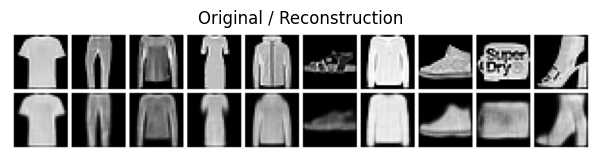

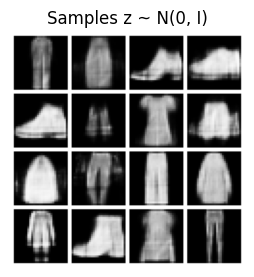

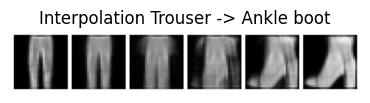

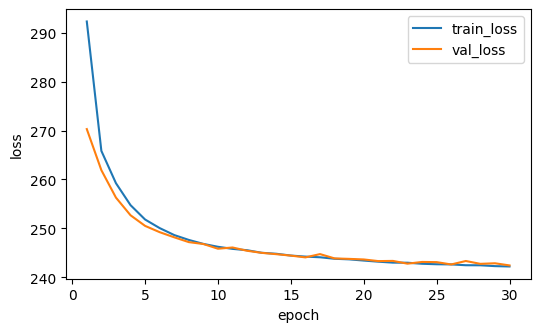

In [9]:
set_seed()
with torch.no_grad():
    recon = vae.decode(vae.encode(x_vis.to(device))[0]).cpu()
    samples = generate(16).cpu()
    z_a, z_b = vae.encode(x_a.to(device))[0], vae.encode(x_b.to(device))[0]
    interp = vae.decode(torch.cat([(1 - a) * z_a + a * z_b for a in ALPHAS])).cpu()

show_grid(torch.cat([x_vis, recon]), nrow=10, title="Original / Reconstruction")
show_grid(samples, nrow=4, title="Samples z ~ N(0, I)")
show_grid(interp, nrow=len(ALPHAS), title="Interpolation Trouser -> Ankle boot")
plot_history(history, ["train_loss", "val_loss"])

In [10]:
save_results(results, {"recon": recon, "samples": samples, "interp": interp})